# Chapitre 1 - Introduction : quatre problèmes d'apprentissage

Ce premier notebook accompagne le chapitre 1 de *The Elements of Statistical Learning*.
Le chapitre ne contient pas de mathématiques : il présente, à travers **quatre jeux de
données réels**, le type de questions que le livre cherche à résoudre. Nous allons :

1. fixer le **vocabulaire** de base (entrées, sorties, apprentissage supervisé ou non,
   régression, classification) ;
2. charger et **visualiser** chacun des quatre exemples du livre :
   courriels *spam*, cancer de la prostate, chiffres manuscrits, micro-puces ADN ;
3. esquisser, pour chacun, la question statistique posée.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from esl.plotting import set_style, COLORS, BLUE, ORANGE, GRAY, SEQ, DIV, TWO_CLASS
from esl import datasets

set_style()
rng = np.random.RandomState(0)

## 1. Le vocabulaire de l'apprentissage statistique

Dans une situation typique, on dispose d'objets (des patients, des courriels, des images…)
décrits par des **variables d'entrée** - appelées aussi *prédicteurs*, *caractéristiques*
(*features*) ou variables explicatives - et, éventuellement, d'une **variable de sortie**
(la *réponse*) que l'on cherche à prédire.

On note en général $X = (X_1, \dots, X_p)$ le vecteur des $p$ entrées et $Y$ (sortie
quantitative) ou $G$ (sortie qualitative) la réponse.

Les données observées forment l'**échantillon d'apprentissage**
$$\mathcal T = \{(x_1, y_1), \dots, (x_N, y_N)\},$$
où $x_i \in \mathbb R^p$ décrit le $i$-ème objet et $y_i$ sa réponse.
À partir de $\mathcal T$, on construit une **règle de prédiction** (un *modèle*,
un *apprenant*) $\hat f$ qui, à une nouvelle entrée $x$, associe une prédiction $\hat f(x)$.
Un bon apprenant prédit correctement la réponse d'objets **qu'il n'a jamais vus**.

**Apprentissage supervisé ou non supervisé.**

- On parle d'apprentissage **supervisé** lorsque la réponse $y_i$ est observée pour les
  objets de l'échantillon : elle « guide » (supervise) la construction de la règle.
- On parle d'apprentissage **non supervisé** lorsque l'on n'observe que les entrées
  $x_1, \dots, x_N$ : il s'agit alors de décrire l'organisation des données
  (groupes, structures, directions privilégiées…). C'est l'objet du chapitre 14.

**Régression ou classification.** Dans le cadre supervisé, on distingue selon la nature de
la sortie :

- **régression** : la sortie est *quantitative* (un prix, un taux, une concentration) ;
- **classification** : la sortie est *qualitative* (catégorielle), à valeurs dans un
  ensemble fini de classes $\mathcal G$ (spam / courriel, chiffre 0 à 9…).

> **Remarque.** Les deux problèmes sont très proches : tous deux consistent à approcher
> une fonction de $X$. Le chapitre 2 les traite dans un cadre commun.

Le tableau ci-dessous résume les quatre exemples du chapitre.

| Exemple | $N$ | $p$ | Sortie | Type de problème |
|---|---|---|---|---|
| Courriels *spam* | 4601 | 57 | spam / courriel | classification supervisée |
| Cancer de la prostate | 97 | 8 | `lpsa` (réel) | régression supervisée |
| Chiffres manuscrits | 7291 + 2007 | 256 | chiffre 0–9 | classification supervisée |
| Micro-puces NCI | 64 | 6830 | aucune | non supervisé |

## 2. Exemple 1 - Détection des courriels indésirables (*spam*)

Les données proviennent de 4601 courriels. Pour chacun, on connaît sa vraie nature
(*spam* ou courriel légitime) et 57 variables : les **fréquences relatives** (en %)
de 48 mots et 6 caractères parmi les plus courants, plus 3 mesures sur les suites de
majuscules. L'objectif est un filtre automatique : c'est un problème de
**classification** à deux classes.

In [2]:
spam = datasets.load_spam()
print(spam.shape)
print("Proportion de spams : %.3f" % spam["spam"].mean())

(4601, 58)
Proportion de spams : 0.394


Les colonnes sont nommées `A.1`, …, `A.57` ; l'ordre est celui de la base *Spambase*
(UCI). Nous attribuons leur nom aux variables utilisées dans le tableau 1.1 du livre.

In [3]:
spam_words = {"george": 27, "you": 19, "your": 21, "hp": 25, "free": 16, "hpl": 26,
              "!": 52, "our": 5, "re": 45, "edu": 46, "remove": 7}
table = pd.DataFrame({w: spam.groupby("spam")["A.%d" % j].mean()
                      for w, j in spam_words.items()}).round(2)
table.index = ["courriel", "spam"]
table

,george,you,your,hp,free,hpl,!,our,re,edu,remove
courriel,1.27,1.27,0.44,0.90,0.07,0.43,0.11,0.18,0.42,0.29,0.01
spam,0.00,2.26,1.38,0.02,0.52,0.01,0.51,0.51,0.13,0.01,0.28


On retrouve le tableau 1.1 du livre : ce sont les mots et caractères dont la fréquence
moyenne diffère le plus entre les deux classes. Le prénom *george* (le destinataire des
courriels) et *hp* (son employeur) signalent un courriel légitime ; *free*, *remove*,
*your* ou le point d'exclamation signalent un spam.

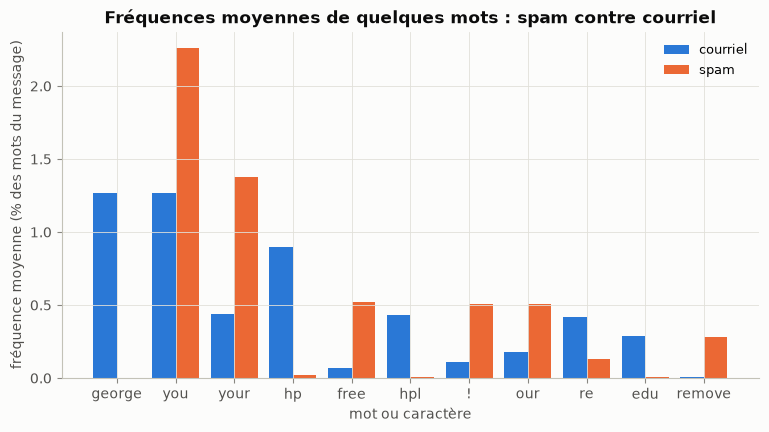

In [4]:
fig, ax = plt.subplots(figsize=(9, 4.5))
pos = np.arange(len(spam_words))
ax.bar(pos - 0.2, table.loc["courriel"], width=0.4, color=BLUE, label="courriel")
ax.bar(pos + 0.2, table.loc["spam"], width=0.4, color=ORANGE, label="spam")
ax.set_xticks(pos)
ax.set_xticklabels(list(spam_words))
ax.set_xlabel("mot ou caractère")
ax.set_ylabel("fréquence moyenne (% des mots du message)")
ax.set_title("Fréquences moyennes de quelques mots : spam contre courriel")
ax.legend()
plt.show()

Le livre propose deux exemples de **règles de décision** simples :

- une règle « en arbre » : spam si $\%\text{george} < 0.6$ **et** $\%\text{you} > 1.5$ ;
- une règle **linéaire** : spam si $0.2\cdot\%\text{you} - 0.3\cdot\%\text{george} > 0$.

Évaluons-les sur les données, à titre de curiosité.

In [5]:
george, you = spam["A.27"], spam["A.19"]
rules = {
    "règle en arbre": (george < 0.6) & (you > 1.5),
    "règle linéaire": 0.2 * you - 0.3 * george > 0,
}
for name, pred in rules.items():
    err = np.mean(pred.astype(int) != spam["spam"])
    print("%-15s : taux d'erreur = %.3f" % (name, err))
print("%-15s : taux d'erreur = %.3f" % ("tout « courriel »", spam["spam"].mean()))

règle en arbre  : taux d'erreur = 0.287
règle linéaire  : taux d'erreur = 0.351
tout « courriel » : taux d'erreur = 0.394


Ces règles, construites « à la main » avec deux variables seulement, améliorent la règle
triviale (tout déclarer courriel, 39 % d'erreur) mais restent très imparfaites : près
d'un message sur trois est mal classé. Tout l'enjeu du livre est d'apprendre
**automatiquement** quelles variables utiliser et comment les combiner.

> **Remarque.** Les deux erreurs ne sont pas équivalentes : classer un vrai courriel en
> spam (et le perdre) est plus grave que laisser passer un spam. On reviendra sur ces
> **coûts asymétriques** (chapitres 2 et 9).

## 3. Exemple 2 - Cancer de la prostate

Les données (Stamey et al., 1989) concernent 97 hommes devant subir une ablation de la
prostate. On cherche à prédire le logarithme du taux d'antigène prostatique spécifique
(`lpsa`) à partir de 8 mesures cliniques :

| variable | signification |
|---|---|
| `lcavol` | log du volume de la tumeur |
| `lweight` | log du poids de la prostate |
| `age` | âge |
| `lbph` | log de la quantité d'hyperplasie bénigne |
| `svi` | envahissement des vésicules séminales (0/1) |
| `lcp` | log de la pénétration capsulaire |
| `gleason` | score de Gleason |
| `pgg45` | pourcentage de scores de Gleason égaux à 4 ou 5 |

La sortie est quantitative : c'est un problème de **régression**.

In [6]:
prostate = datasets.load_prostate()
variables = ["lpsa", "lcavol", "lweight", "age", "lbph", "svi", "lcp", "gleason", "pgg45"]
prostate[variables].describe().round(2)

,lpsa,lcavol,lweight,age,lbph,svi,lcp,gleason,pgg45
count,97.00,97.00,97.00,97.00,97.00,97.00,97.00,97.00,97.00
mean,2.48,1.35,3.63,63.87,0.10,0.22,-0.18,6.75,24.38
std,1.15,1.18,0.43,7.45,1.45,0.41,1.40,0.72,28.20
min,-0.43,-1.35,2.37,41.00,-1.39,0.00,-1.39,6.00,0.00
25%,1.73,0.51,3.38,60.00,-1.39,0.00,-1.39,6.00,0.00
50%,2.59,1.45,3.62,65.00,0.30,0.00,-0.80,7.00,15.00
75%,3.06,2.13,3.88,68.00,1.56,0.00,1.18,7.00,40.00
max,5.58,3.82,4.78,79.00,2.33,1.00,2.90,9.00,100.00


La figure 1.1 du livre est une **matrice de nuages de points** : chaque case $(i, j)$
représente la variable $j$ (abscisse) contre la variable $i$ (ordonnée). On la
reproduit ci-dessous, avec les histogrammes sur la diagonale.

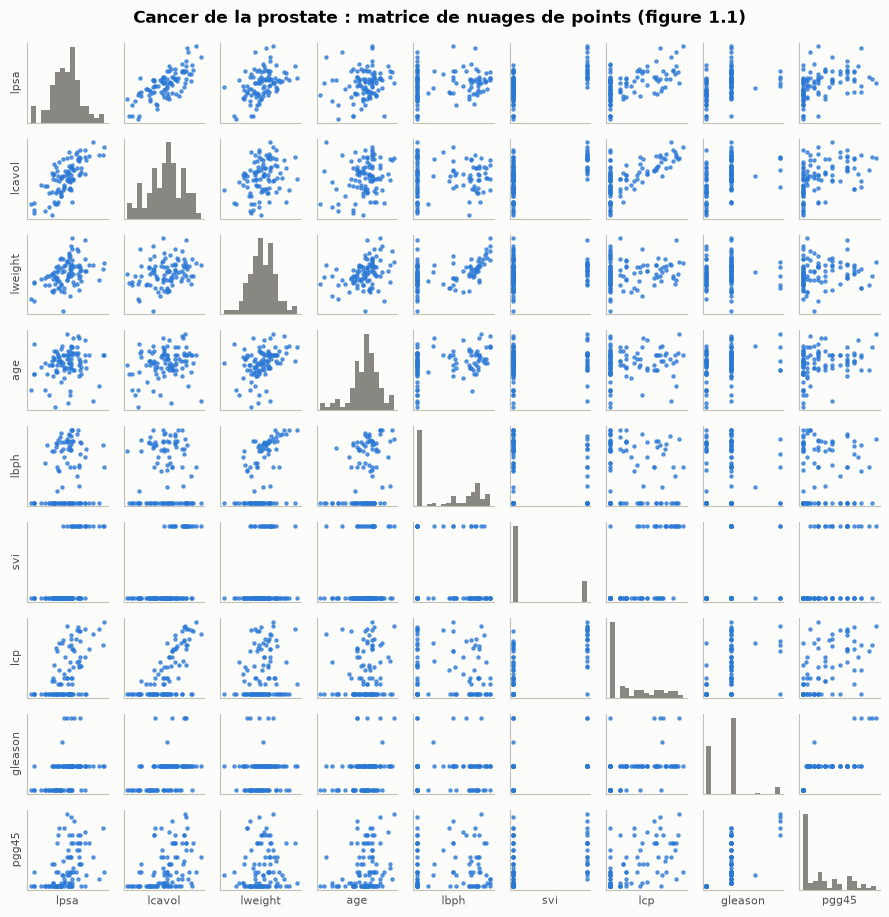

In [7]:
def scatter_matrix(df, cols, color=BLUE, figsize=(11, 11)):
    """Matrice de nuages de points simple (histogrammes sur la diagonale)."""
    n = len(cols)
    fig, axes = plt.subplots(n, n, figsize=figsize)
    for i, ci in enumerate(cols):
        for j, cj in enumerate(cols):
            ax = axes[i, j]
            if i == j:
                ax.hist(df[ci], bins=15, color=GRAY)
            else:
                ax.scatter(df[cj], df[ci], s=5, color=color, alpha=0.7)
            ax.set_xticks([])
            ax.set_yticks([])
            ax.grid(False)
            if i == n - 1:
                ax.set_xlabel(cj, fontsize=8)
            if j == 0:
                ax.set_ylabel(ci, fontsize=8)
    return fig, axes


fig, axes = scatter_matrix(prostate, variables)
fig.suptitle("Cancer de la prostate : matrice de nuages de points (figure 1.1)",
             fontweight="bold", y=0.91)
plt.show()

La première ligne montre `lpsa` en fonction de chaque prédicteur. Une relation croissante
avec `lcavol` (volume de la tumeur) saute aux yeux ; `svi` et `gleason` ne prennent que
quelques valeurs (variables discrètes). Quantifions ces liens par les corrélations.

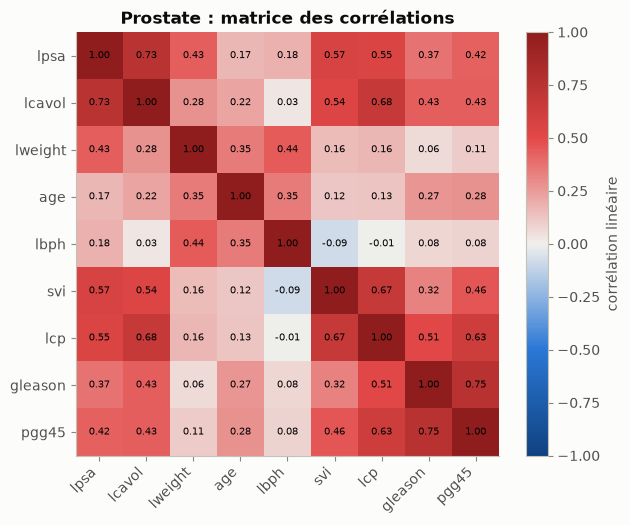

In [8]:
corr = prostate[variables].corr()
fig, ax = plt.subplots(figsize=(7, 5.5))
im = ax.imshow(corr, cmap=DIV, vmin=-1, vmax=1)
ax.set_xticks(range(len(variables)))
ax.set_xticklabels(variables, rotation=45, ha="right")
ax.set_yticks(range(len(variables)))
ax.set_yticklabels(variables)
ax.grid(False)
for i in range(len(variables)):
    for j in range(len(variables)):
        ax.text(j, i, "%.2f" % corr.iloc[i, j], ha="center", va="center", fontsize=7)
fig.colorbar(im, ax=ax, label="corrélation linéaire")
ax.set_title("Prostate : matrice des corrélations")
plt.show()

> **À retenir.** Certaines corrélations avec `lpsa` sont nettes (`lcavol` : 0,73 ;
> `svi` : 0,57 ; `lcp` : 0,55), mais les prédicteurs sont aussi corrélés **entre eux**.
> Construire « à l'œil » un bon modèle prédictif est donc difficile : c'est ce que fera
> la régression linéaire au chapitre 3.

## 4. Exemple 3 - Reconnaissance de chiffres manuscrits

Les images proviennent de codes postaux manuscrits sur des enveloppes du service postal
américain. Chaque image isole un chiffre et est une matrice $16\times 16$ de niveaux de
gris (ici ramenés à l'intervalle $[-1, 1]$). Une image est donc un vecteur
$x \in \mathbb R^{256}$, et il faut prédire sa classe $G \in \{0, 1, \dots, 9\}$ :
c'est un problème de **classification à 10 classes**.

In [9]:
X_zip, y_zip = datasets.load_zip("train")
X_zip_test, y_zip_test = datasets.load_zip("test")
print("apprentissage :", X_zip.shape, " test :", X_zip_test.shape)
print("effectifs par chiffre :", np.bincount(y_zip))

apprentissage : (7291, 256)  test : (2007, 256)
effectifs par chiffre : [1194 1005  731  658  652  556  664  645  542  644]


Affichons, comme la figure 1.2 du livre, quelques exemples de chaque chiffre
(une ligne par chiffre). Un pixel à $-1$ est blanc, un pixel à $+1$ est noir.

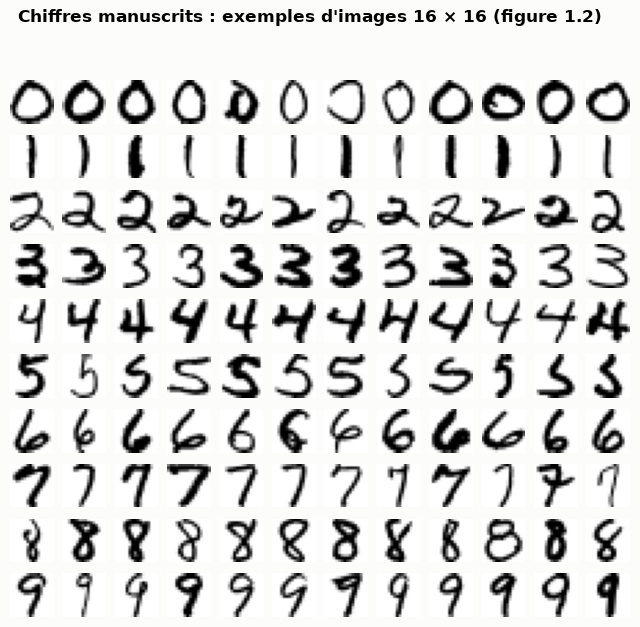

In [10]:
n_per_digit = 12
fig, axes = plt.subplots(10, n_per_digit, figsize=(8, 7))
for d in range(10):
    idx = rng.choice(np.flatnonzero(y_zip == d), n_per_digit, replace=False)
    for j, i in enumerate(idx):
        ax = axes[d, j]
        ax.imshow(X_zip[i].reshape(16, 16), cmap="gray_r", vmin=-1, vmax=1)
        ax.axis("off")
fig.suptitle("Chiffres manuscrits : exemples d'images 16 × 16 (figure 1.2)",
             fontweight="bold")
plt.show()

La variabilité est grande (épaisseur du trait, inclinaison, forme du 4 ou du 7…),
bien que les images aient été normalisées en taille et en orientation. L'**image
moyenne** de chaque classe donne une idée du « prototype » de chaque chiffre.

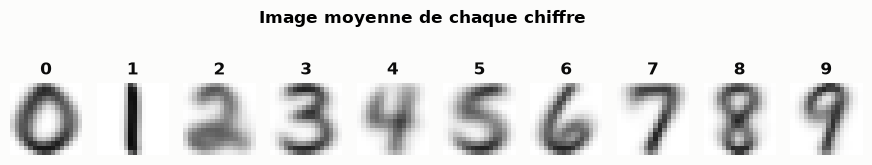

In [11]:
fig, axes = plt.subplots(1, 10, figsize=(11, 1.8))
for d in range(10):
    axes[d].imshow(X_zip[y_zip == d].mean(0).reshape(16, 16), cmap="gray_r", vmin=-1, vmax=1)
    axes[d].set_title(str(d))
    axes[d].axis("off")
fig.suptitle("Image moyenne de chaque chiffre", fontweight="bold", y=1.1)
plt.show()

> **Remarque.** Pour trier le courrier, le taux d'erreur doit être très faible. Le livre
> note qu'on peut s'autoriser une classe « je ne sais pas » pour les images ambiguës,
> triées ensuite à la main (on parle d'*option de rejet*).

## 5. Exemple 4 - Micro-puces à ADN (données NCI60)

Une **micro-puce** mesure simultanément l'expression de milliers de gènes dans un
échantillon de cellules. Pour chaque gène, on obtient un nombre - un logarithme de
rapport d'intensités, typiquement entre $-6$ et $6$ - positif si le gène est plus
exprimé dans l'échantillon que dans la référence, négatif sinon.

Les données NCI comportent **6830 gènes** mesurés sur **64 lignées cancéreuses**
de types différents (sein, mélanome, leucémie…).

In [12]:
X_nci, labels_nci = datasets.load_nci()
print(X_nci.shape)
pd.Series(labels_nci).value_counts()

(64, 6830)


RENAL          9
NSCLC          9
MELANOMA       8
BREAST         7
COLON          7
OVARIAN        6
LEUKEMIA       6
CNS            5
PROSTATE       2
UNKNOWN        1
K562B-repro    1
K562A-repro    1
MCF7A-repro    1
MCF7D-repro    1
Name: count, dtype: int64

La figure 1.3 du livre représente les données par une **carte de chaleur** (*heat map*) :
une ligne par gène (100 gènes tirés au hasard, pour la lisibilité), une colonne par
échantillon, et une couleur divergente selon le signe de l'expression.